# Part 3: Patient Profiles (Unsupervised Learning)

Groups similar patients without using the diagnosis (`cardio`) and checks how the disease rate differs between groups. The agent (Part 4) uses these profiles to explain a patient's result.

## 1. Load the data

Same preparation and splits as Parts 1–2 (`cardio_utils.py`).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score

from cardio_utils import load_clean_data, split_and_scale, RANDOM_STATE

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

data = split_and_scale(load_clean_data())
FEATURES = data["features"]
X_train, X_train_s, y_train = data["X_train"], data["X_train_s"], data["y_train"]
X_val,   X_val_s,   y_val   = data["X_val"],   data["X_val_s"],   data["y_val"]

print("Features:", FEATURES)
print("Training patients:", len(X_train))

Features: ['ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi', 'is_male']
Training patients: 47991


## 2. Approach

`cardio` is hidden from the clustering and used only afterwards to describe the groups; scaled features are used.

## 3. PCA

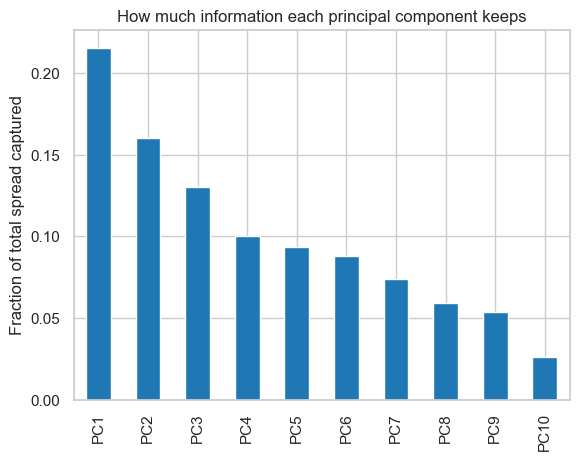

PC1 + PC2 keep 38% of the spread


In [2]:
pca = PCA(random_state=RANDOM_STATE).fit(X_train_s)

explained = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(FEATURES))])
explained.plot(kind="bar", color="tab:blue")
plt.ylabel("Fraction of total spread captured")
plt.title("How much information each principal component keeps")
plt.show()

print(f"PC1 + PC2 keep {explained.iloc[:2].sum():.0%} of the spread")

PC1 + PC2 keep only 38% of the variance.

### PCA loadings

In [3]:
loadings = pd.DataFrame(pca.components_[:2], columns=FEATURES, index=["PC1", "PC2"]).round(2)
loadings

,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi,is_male
PC1,0.55,0.53,0.36,0.28,0.03,0.06,-0.00,0.27,0.34,0.02
PC2,0.07,0.09,-0.11,-0.12,0.61,0.50,0.05,-0.12,-0.13,0.55


PC1 is an overall health-risk axis (blood pressure, cholesterol, BMI, age); PC2 is a male smoker/drinker axis.

### Validation patients coloured by diagnosis

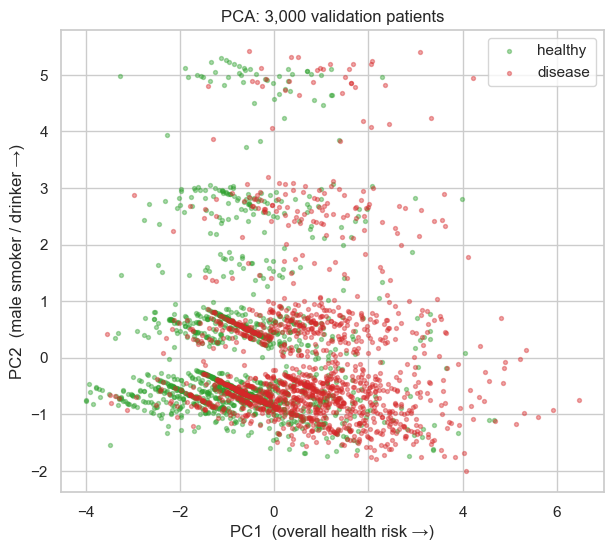

In [4]:
sample = np.random.RandomState(RANDOM_STATE).choice(len(X_val_s), 3000, replace=False)
pcs = pca.transform(X_val_s[sample])[:, :2]

plt.figure(figsize=(7, 6))
for label, colour, name in [(0, "tab:green", "healthy"), (1, "tab:red", "disease")]:
    mask = y_val.values[sample] == label
    plt.scatter(pcs[mask, 0], pcs[mask, 1], s=8, alpha=0.4, c=colour, label=name)
plt.xlabel("PC1  (overall health risk →)")
plt.ylabel("PC2  (male smoker / drinker →)")
plt.title("PCA: 3,000 validation patients")
plt.legend()
plt.show()

The two classes overlap heavily, which limits the accuracy any model can reach.

## 4. LDA

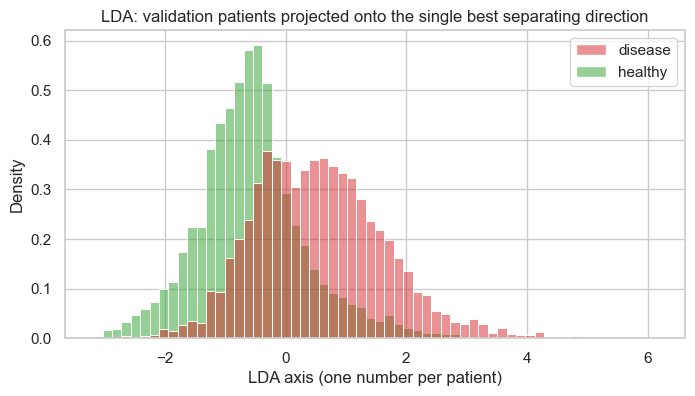

Which features the LDA direction is made of (bigger = more important):
ap_hi          0.86
age_years      0.36
cholesterol    0.33
bmi            0.15
ap_lo          0.10
active        -0.09
gluc          -0.06
smoke         -0.04
alco          -0.04
is_male        0.02
dtype: float64

LDA as a classifier, validation ROC-AUC: 0.795


In [5]:
lda = LinearDiscriminantAnalysis().fit(X_train_s, y_train)
lda_val = lda.transform(X_val_s).ravel()

plt.figure(figsize=(8, 4))
sns.histplot(x=lda_val, hue=y_val.map({0: "healthy", 1: "disease"}).values, bins=60,
             palette={"healthy": "tab:green", "disease": "tab:red"}, stat="density", common_norm=False)
plt.xlabel("LDA axis (one number per patient)")
plt.title("LDA: validation patients projected onto the single best separating direction")
plt.show()

weights = pd.Series(lda.coef_[0], index=FEATURES).sort_values(key=abs, ascending=False).round(2)
print("Which features the LDA direction is made of (bigger = more important):")
print(weights)
print(f"\nLDA as a classifier, validation ROC-AUC: {roc_auc_score(y_val, lda.decision_function(X_val_s)):.3f}")

The LDA direction is dominated by `ap_hi`, `age_years` and `cholesterol`; its AUC (0.795) is close to the MLP, so the signal is mostly linear.

## 5. K-means

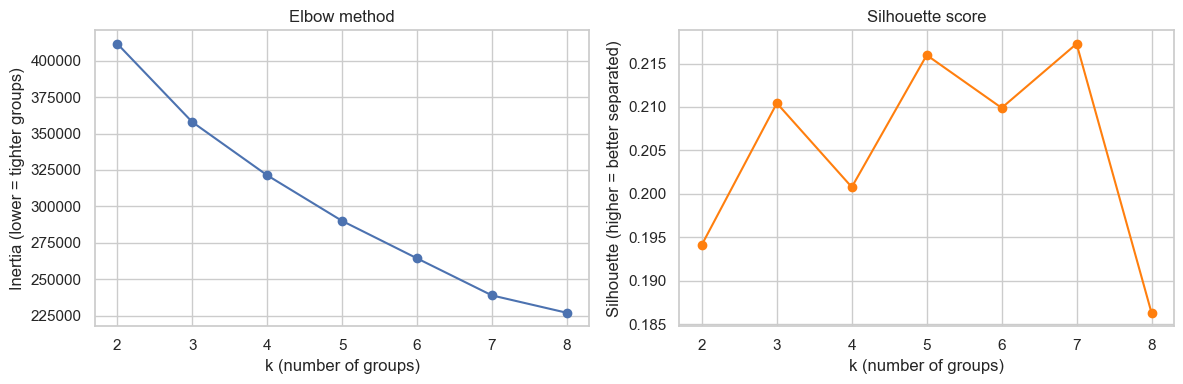

,k,inertia,silhouette
0,2,411702.251,0.194
1,3,357955.161,0.210
2,4,321357.793,0.201
3,5,290016.962,0.216
4,6,264291.806,0.210
5,7,238838.200,0.217
6,8,226882.880,0.186


In [6]:
silhouette_sample = np.random.RandomState(0).choice(len(X_train_s), 5000, replace=False)   # silhouette is slow on 48k rows

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train_s)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X_train_s[silhouette_sample], km.labels_[silhouette_sample])})
k_table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o")
axes[0].set(title="Elbow method", xlabel="k (number of groups)", ylabel="Inertia (lower = tighter groups)")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="tab:orange")
axes[1].set(title="Silhouette score", xlabel="k (number of groups)", ylabel="Silhouette (higher = better separated)")
plt.tight_layout()
plt.show()

k_table.round(3)

No sharp elbow and silhouette ≈ 0.2 for every k; k = 4 is chosen because it gives four distinct, interpretable groups.

In [7]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_train_s)

train_cluster = kmeans.labels_
val_cluster = kmeans.predict(X_val_s)

print("Patients per group (training):", np.bincount(train_cluster))

Patients per group (training): [13158 25747  4494  4592]


## 6. Describe and name the groups

In [8]:
profile = X_train.copy()
profile["cluster"] = train_cluster
profile["disease_rate"] = y_train.values

summary = profile.groupby("cluster").mean()
summary["n_patients"] = profile["cluster"].value_counts().sort_index()

overall = X_train.mean()
summary.round(2)

,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi,is_male,disease_rate,n_patients
cluster,,,,,,,,,,,,
0,143.47,89.94,1.51,1.08,0.00,0.03,0.81,55.52,30.44,0.30,0.79,13158
1,117.49,76.61,1.11,1.04,0.00,0.01,0.80,51.94,25.77,0.29,0.33,25747
2,127.48,81.85,1.32,1.15,0.90,0.38,0.84,52.22,26.76,0.89,0.46,4494
3,129.78,82.71,2.37,2.76,0.03,0.03,0.79,55.72,28.99,0.27,0.62,4592


Groups are named by their most distinctive feature, since cluster numbers can change between runs.

In [9]:
names = {}
names[summary["ap_hi"].idxmax()] = "High blood pressure & overweight"
names[summary["smoke"].idxmax()] = "Smokers & drinkers"
names[summary["gluc"].idxmax()] = "High cholesterol & sugar"
for c in range(K):
    names.setdefault(c, "Lower-risk baseline")
assert len(set(names.values())) == K, "two rules picked the same group — inspect the summary table"

summary["name"] = summary.index.map(names)
cols = ["name", "n_patients", "disease_rate", "ap_hi", "ap_lo", "cholesterol", "gluc",
        "smoke", "alco", "age_years", "bmi", "is_male"]
summary[cols].sort_values("disease_rate", ascending=False).round(2)

,name,n_patients,disease_rate,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,age_years,bmi,is_male
cluster,,,,,,,,,,,,
0,High blood pressure & overweight,13158,0.79,143.47,89.94,1.51,1.08,0.00,0.03,55.52,30.44,0.30
3,High cholesterol & sugar,4592,0.62,129.78,82.71,2.37,2.76,0.03,0.03,55.72,28.99,0.27
2,Smokers & drinkers,4494,0.46,127.48,81.85,1.32,1.15,0.90,0.38,52.22,26.76,0.89
1,Lower-risk baseline,25747,0.33,117.49,76.61,1.11,1.04,0.00,0.01,51.94,25.77,0.29


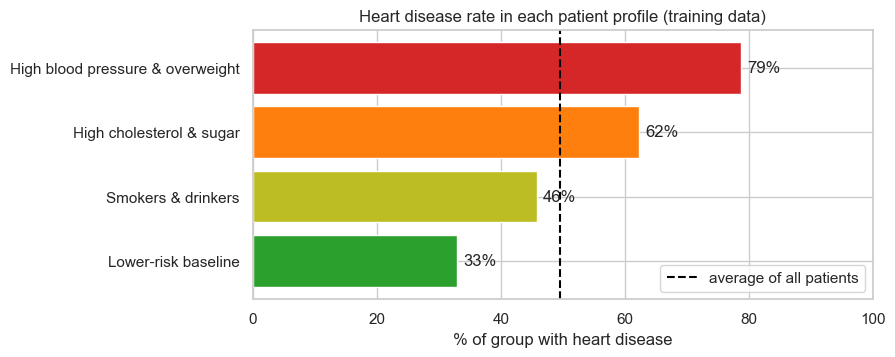

In [10]:
order = summary.sort_values("disease_rate")
plt.figure(figsize=(8, 3.5))
bars = plt.barh(order["name"], order["disease_rate"] * 100,
                color=["tab:green", "tab:olive", "tab:orange", "tab:red"])
plt.axvline(y_train.mean() * 100, color="black", linestyle="--", label="average of all patients")
for bar, rate in zip(bars, order["disease_rate"]):
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{rate:.0%}", va="center")
plt.xlabel("% of group with heart disease")
plt.xlim(0, 100)
plt.title("Heart disease rate in each patient profile (training data)")
plt.legend(loc="lower right")
plt.show()

| Profile | Distinctive features | Disease rate |
|---|---|---|
| **High blood pressure & overweight** | BP ≈ 143/90, BMI ≈ 30, age ≈ 55.5 | ≈ **79%** |
| **High cholesterol & sugar** | cholesterol and glucose far above normal, age ≈ 55.7 | ≈ **62%** |
| **Smokers & drinkers** | 90% smoke, 38% drink, 89% men | ≈ **46%** |
| **Lower-risk baseline** | BP ≈ 117/77, normal cholesterol, age ≈ 52 | ≈ **33%** |

K-means never saw `cardio`, yet the disease rate ranges from 33% to 79%.

### Groups on the PCA plot

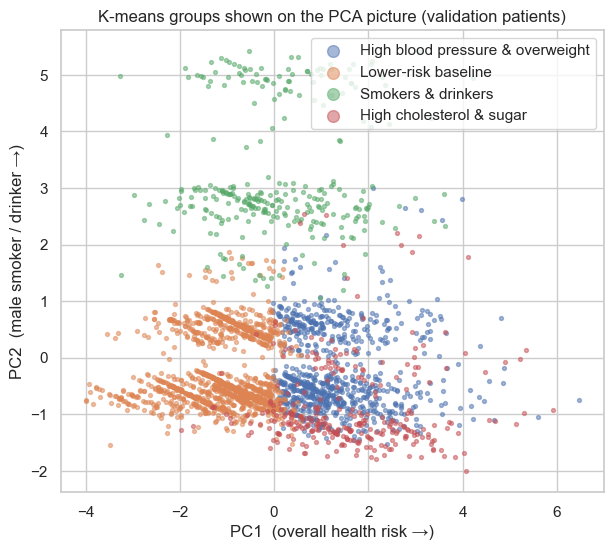

In [11]:
cluster_sample = val_cluster[sample]
plt.figure(figsize=(7, 6))
for c in range(K):
    mask = cluster_sample == c
    plt.scatter(pcs[mask, 0], pcs[mask, 1], s=8, alpha=0.5, label=names[c])
plt.xlabel("PC1  (overall health risk →)")
plt.ylabel("PC2  (male smoker / drinker →)")
plt.title("K-means groups shown on the PCA picture (validation patients)")
plt.legend(markerscale=3)
plt.show()

The groups occupy distinct but touching regions; there are no sharp boundaries.

## 7. Self-organising map (SOM)

In [12]:
GRID = 10
N_ITERATIONS = 20_000
LR_START, SIGMA_START = 0.5, 3.0

som_rng = np.random.RandomState(RANDOM_STATE)
n_features = X_train_s.shape[1]

grid_pos = np.array([(r, c) for r in range(GRID) for c in range(GRID)])

weights = X_train_s[som_rng.choice(len(X_train_s), GRID * GRID, replace=False)].copy()

for t in range(N_ITERATIONS):
    fraction = t / N_ITERATIONS
    lr = LR_START * (1 - fraction)
    sigma = SIGMA_START * (1 - fraction) + 0.5

    x = X_train_s[som_rng.randint(len(X_train_s))]
    winner = np.argmin(((weights - x) ** 2).sum(axis=1))
    grid_dist2 = ((grid_pos - grid_pos[winner]) ** 2).sum(axis=1)
    h = np.exp(-grid_dist2 / (2 * sigma ** 2))
    weights += lr * h[:, None] * (x - weights)

print("SOM trained ✔")

SOM trained ✔


### Disease rate per neuron

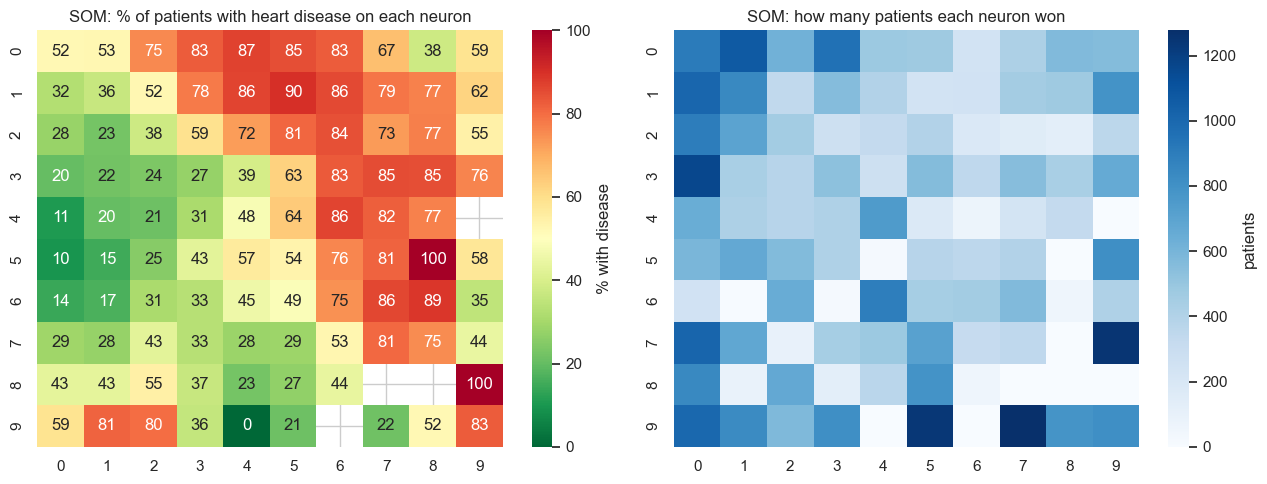

In [13]:
def best_matching_unit(X):
    d2 = ((X[:, None, :] - weights[None, :, :]) ** 2).sum(axis=2)
    return d2.argmin(axis=1)

train_bmu = np.concatenate([best_matching_unit(chunk) for chunk in np.array_split(X_train_s, 20)])

som_df = pd.DataFrame({"bmu": train_bmu, "cardio": y_train.values, "cluster": train_cluster})
disease_map = som_df.groupby("bmu")["cardio"].mean().reindex(range(GRID * GRID)).values.reshape(GRID, GRID)
count_map = som_df["bmu"].value_counts().reindex(range(GRID * GRID), fill_value=0).values.reshape(GRID, GRID)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(disease_map * 100, ax=axes[0], cmap="RdYlGn_r", vmin=0, vmax=100, annot=True, fmt=".0f",
            cbar_kws={"label": "% with disease"})
axes[0].set_title("SOM: % of patients with heart disease on each neuron")
sns.heatmap(count_map, ax=axes[1], cmap="Blues", cbar_kws={"label": "patients"})
axes[1].set_title("SOM: how many patients each neuron won")
plt.tight_layout()
plt.show()

High- and low-risk neurons form connected regions, although the SOM never saw `cardio`.

### Component planes

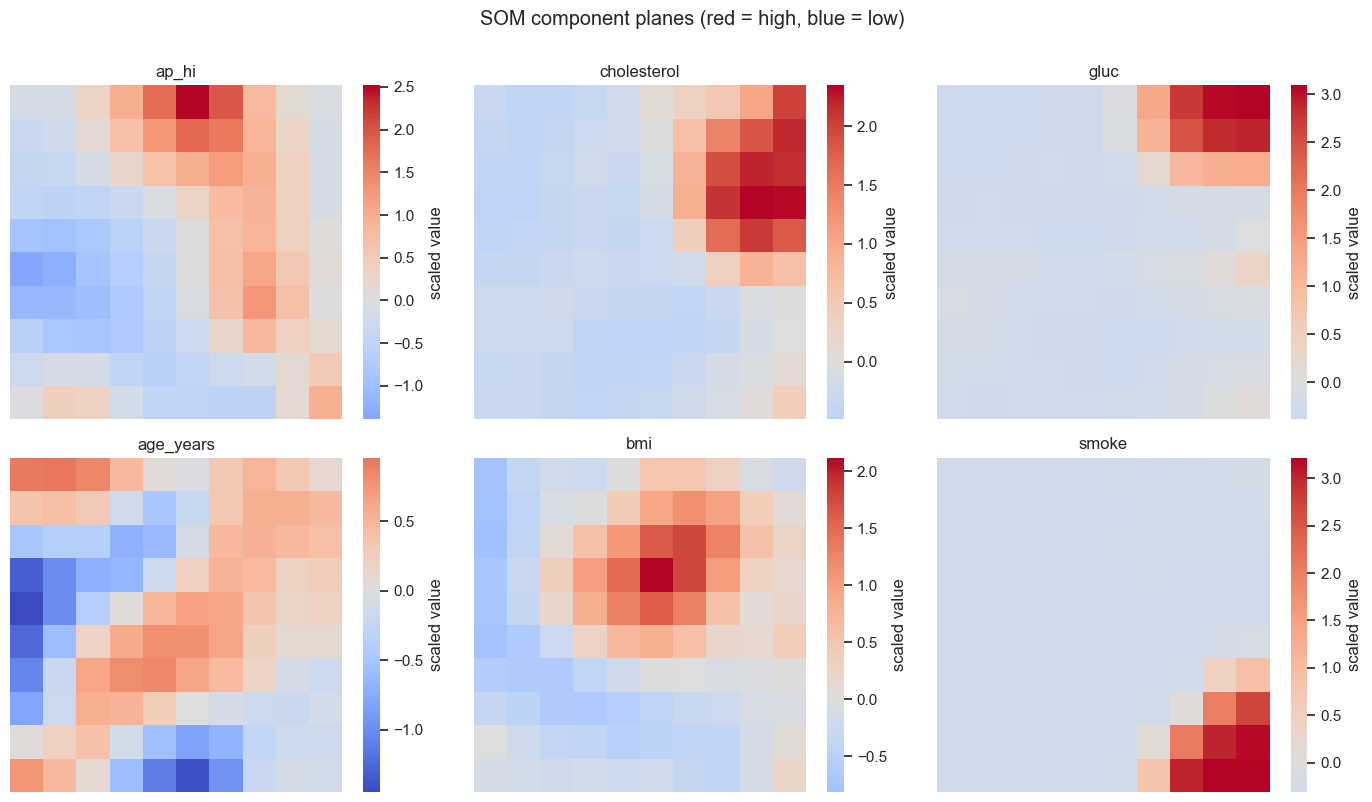

In [14]:
show = ["ap_hi", "cholesterol", "gluc", "age_years", "bmi", "smoke"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feat in zip(axes.ravel(), show):
    plane = weights[:, FEATURES.index(feat)].reshape(GRID, GRID)
    sns.heatmap(plane, ax=ax, cmap="coolwarm", center=0, cbar_kws={"label": "scaled value"})
    ax.set_title(feat)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("SOM component planes (red = high, blue = low)", y=1.0)
plt.tight_layout()
plt.show()

The high-disease region lines up with high `ap_hi`, matching the k-means profiles.

### Agreement with k-means

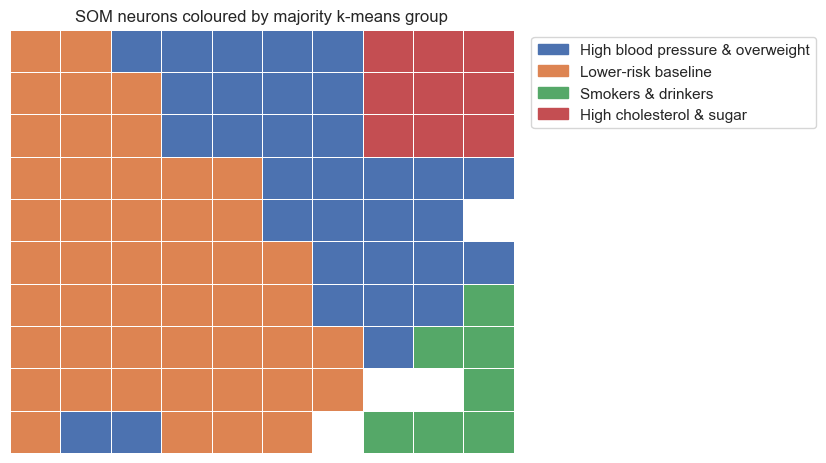

In [15]:
majority = som_df.groupby("bmu")["cluster"].agg(lambda s: s.value_counts().idxmax())
cluster_map = majority.reindex(range(GRID * GRID)).values.reshape(GRID, GRID)

palette = sns.color_palette(n_colors=K)
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cluster_map, cmap=palette, cbar=False, linewidths=0.5, linecolor="white")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[c]) for c in range(K)]
plt.legend(handles, [names[c] for c in range(K)], bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("SOM neurons coloured by majority k-means group")
plt.xticks([]); plt.yticks([])
plt.show()

Each k-means group occupies mostly one connected SOM region, so the profiles reflect real structure.

## 8. Predictive value of the profiles

In [16]:
group_rate = summary["disease_rate"]
profile_only_score = group_rate.values[val_cluster]
profile_auc = roc_auc_score(y_val, profile_only_score)

comparison = pd.Series({
    "Random guessing": 0.5,
    "Profile only (4 groups, no labels used to form them)": profile_auc,
    "LDA (linear, 10 features)": roc_auc_score(y_val, lda.decision_function(X_val_s)),
    "MLP from Parts 1–2 (≈)": 0.80,
}).round(3)
comparison

Random guessing                                         0.500
Profile only (4 groups, no labels used to form them)    0.709
LDA (linear, 10 features)                               0.795
MLP from Parts 1–2 (≈)                                  0.800
dtype: float64

The profile alone gives AUC 0.709 vs 0.800 for the MLP, so profiles explain the result while the MLP gives the risk number.

## 9. Save the profiles

In [17]:
Path("results").mkdir(exist_ok=True)

profiles = {
    "k": K,
    "features": FEATURES,
    "centres_scaled": kmeans.cluster_centers_.round(6).tolist(),
    "groups": [
        {
            "cluster": int(c),
            "name": names[c],
            "n_patients": int(summary.loc[c, "n_patients"]),
            "disease_rate": round(float(summary.loc[c, "disease_rate"]), 4),
            "average_patient": summary.loc[c, FEATURES].astype(float).round(2).to_dict(),
        }
        for c in range(K)
    ],
    "validation_auc_profile_only": round(float(profile_auc), 4),
}
with open("results/patient_profiles.json", "w") as f:
    json.dump(profiles, f, indent=2)

for g in sorted(profiles["groups"], key=lambda g: -g["disease_rate"]):
    print(f"{g['name']:<35} {g['n_patients']:>6} patients   disease rate {g['disease_rate']:.0%}")

High blood pressure & overweight     13158 patients   disease rate 79%
High cholesterol & sugar              4592 patients   disease rate 62%
Smokers & drinkers                    4494 patients   disease rate 46%
Lower-risk baseline                  25747 patients   disease rate 33%


## Summary

Four patient profiles (disease rate 33% → 79%), confirmed by the SOM, are saved to `results/patient_profiles.json`. Limitation: low silhouette (≈ 0.2) means soft rather than sharply separated groups.